https://www.facebook.com/photo/?fbid=4105152116165537&set=pb.100058739353404.-2207520000

In [ ]:
import cv2
import os

# Step 1: Load the image
image_path = "/content/test.jpg"
img = cv2.imread(image_path)

# Check whether image is loaded successfully
if img is None:
    print("Error: Image not found!")
else:
    # Step 2: Extract image dimensions
    height, width = img.shape[:2]

    # Step 3: Extract number of channels
    channels = 1 if len(img.shape) == 2 else img.shape[2]

    # Step 4: Extract total number of pixels
    total_pixels = height * width

    # Step 5: Extract image data type
    data_type = img.dtype

    # Step 6: Extract minimum and maximum pixel values
    min_pixel = img.min()
    max_pixel = img.max()

    # Display results
    print("IMAGE INFORMATION")
    print("Image Shape:", img.shape)
    print("Image Width:", width)
    print("Image Height:", height)
    print("Number of Channels:", channels)
    print("Total Pixels:", total_pixels)
    print("Data Type:", data_type)
    print("Minimum Pixel Value:", min_pixel)
    print("Maximum Pixel Value:", max_pixel)

IMAGE INFORMATION
Image Shape: (597, 335, 3)
Image Width: 335
Image Height: 597
Number of Channels: 3
Total Pixels: 199995
Data Type: uint8
Minimum Pixel Value: 0
Maximum Pixel Value: 255


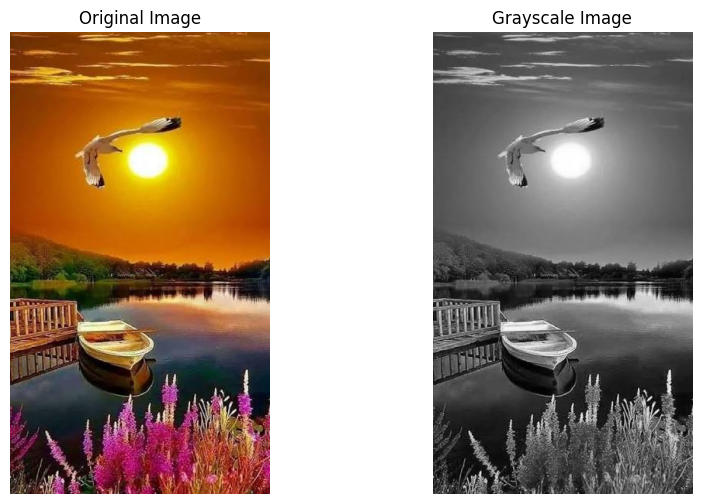

GRAYSCALE IMAGE INFORMATION
---------------------------
Grayscale Shape: (597, 335)
Width: 335
Height: 597
Minimum Intensity: 0
Maximum Intensity: 255
Data Type: uint8


In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load original image
img = cv2.imread("/content/test.jpg")

# Convert BGR image into grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Display both images
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.show()

# Display grayscale information
print("GRAYSCALE IMAGE INFORMATION")
print("---------------------------")
print("Grayscale Shape:", gray.shape)
print("Width:", gray.shape[1])
print("Height:", gray.shape[0])
print("Minimum Intensity:", gray.min())
print("Maximum Intensity:", gray.max())
print("Data Type:", gray.dtype)

In [ ]:
def cubic_kernel(s):
    a = -0.5
    r = abs(s)

    if 0 <= r <= 1:
        return (a + 2) * r**3 - (a + 3) * r**2 + 1

    elif 1 < r < 2:
        return a * r**3 - 5*a*r**2 + 8*a*r - 4*a

    else:
        return 0

In [ ]:
test_values = [0, 0.5, 1, 1.5, 2, 2.5]

for s in test_values:
    print(f"w({s}) = {cubic_kernel(s):.4f}")

w(0) = 1.0000
w(0.5) = 0.5625
w(1) = 0.0000
w(1.5) = -0.0625
w(2) = 0.0000
w(2.5) = 0.0000


In [ ]:
# Original grayscale image dimensions
height, width = gray.shape

# Calculate new dimensions (2x scaling)
new_width = round(2 * width)
new_height = round(2 * height)

print("OUTPUT IMAGE DIMENSIONS")
print("Original Width:", width)
print("Original Height:", height)
print("New Width:", new_width)
print("New Height:", new_height)
print("Scaling Factor: 2x")

OUTPUT IMAGE DIMENSIONS
Original Width: 335
Original Height: 597
New Width: 670
New Height: 1194
Scaling Factor: 2x


In [ ]:
# Test output-to-input coordinate mapping
test_coordinates = [(0, 0), (2, 2), (10, 20), (100, 200)]

for x_out, y_out in test_coordinates:
    x = x_out / 2
    y = y_out / 2

    print(f"Output ({x_out}, {y_out}) -> Input ({x}, {y})")

Output (0, 0) -> Input (0.0, 0.0)
Output (2, 2) -> Input (1.0, 1.0)
Output (10, 20) -> Input (5.0, 10.0)
Output (100, 200) -> Input (50.0, 100.0)


In [ ]:
import numpy as np

# Select an example input coordinate
x = 0
y = 0

# Find integer coordinates
i = int(np.floor(x))
j = int(np.floor(y))

# Generate 4x4 neighborhood indices
columns = np.arange(i - 1, i + 3)
rows = np.arange(j - 1, j + 3)

# Apply edge replication
columns = np.clip(columns, 0, width - 1)
rows = np.clip(rows, 0, height - 1)

# Extract 4x4 neighborhood
neighborhood = gray[np.ix_(rows, columns)]

print("Column indices:", columns)
print("Row indices:", rows)

print("\n4x4 Neighborhood:")
print(neighborhood)

Column indices: [0 0 1 2]
Row indices: [0 0 1 2]

4x4 Neighborhood:
[[80 80 80 79]
 [80 80 80 79]
 [79 79 79 79]
 [64 64 67 69]]


The neighborhood is a 4×4 matrix containing grayscale intensity values from your original image.

Why use np.clip()?

It implements edge replication:
- Negative indices become 0.
- Indices beyond the image boundary become the last valid index.
- Valid indices remain unchanged.
This ensures that we never access pixels outside the original image.

In [ ]:
import numpy as np

def bicubic_pixel(gray, x, y):
    height, width = gray.shape

    # Find integer coordinates
    i = int(np.floor(x))
    j = int(np.floor(y))

    result = 0.0

    # Select 4x4 neighborhood
    for n in range(j - 1, j + 3):
        for m in range(i - 1, i + 3):

            # Edge replication
            row = np.clip(n, 0, height - 1)
            col = np.clip(m, 0, width - 1)

            # Get neighboring pixel intensity
            pixel = gray[row, col]

            # Calculate horizontal and vertical weights
            wx = cubic_kernel(x - m)
            wy = cubic_kernel(y - n)

            # Apply 2D bicubic formula
            result += pixel * wx * wy

    # Round and clip intensity
    result = np.clip(round(result), 0, 255)

    return int(result)


# Test the first output pixel
value = bicubic_pixel(gray, 0, 0)

print("BICUBIC INTERPOLATION")
print("Input Coordinate: (0, 0)")
print("Interpolated Pixel Value:", value)

BICUBIC INTERPOLATION
Input Coordinate: (0, 0)
Interpolated Pixel Value: 80


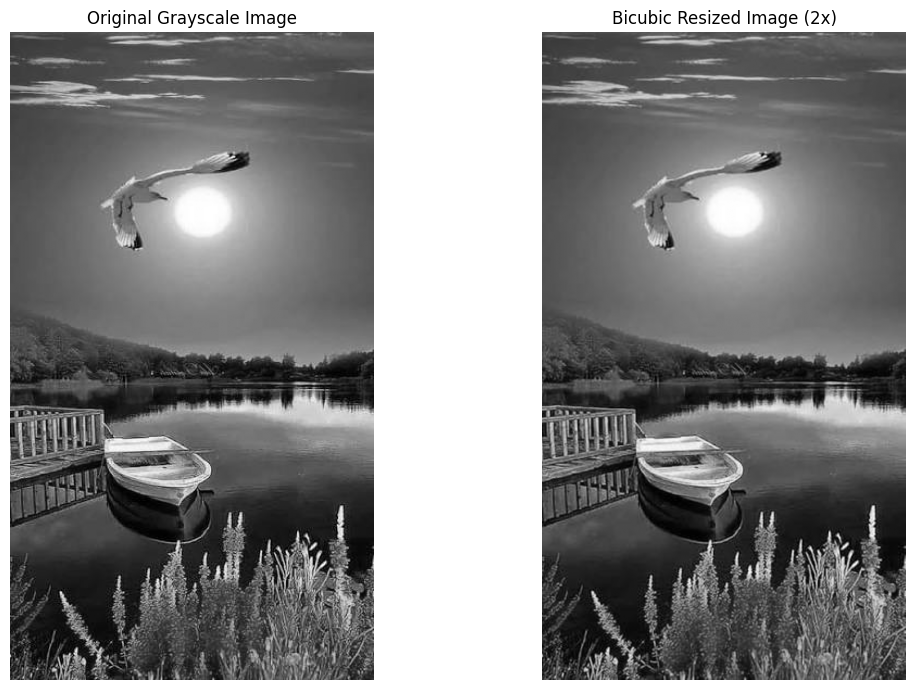

BICUBIC RESIZING COMPLETED
Original Shape: (597, 335)
Resized Shape: (1194, 670)
Output Width: 670
Output Height: 1194
Output Data Type: uint8
Minimum Intensity: 0
Maximum Intensity: 255
Saved as: bicubic_output.png


In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Create output image
output = np.zeros((new_height, new_width), dtype=np.uint8)

# Process each output row
for y_out in range(new_height):

    y = y_out / 2
    j = int(np.floor(y))

    # Four neighboring rows
    rows = np.arange(j - 1, j + 3)
    wy = np.array([cubic_kernel(y - n) for n in range(j - 1, j + 3)])

    # Apply edge replication
    rows = np.clip(rows, 0, height - 1)

    for x_out in range(new_width):

        x = x_out / 2
        i = int(np.floor(x))

        # Four neighboring columns
        cols = np.arange(i - 1, i + 3)
        wx = np.array([cubic_kernel(x - m) for m in range(i - 1, i + 3)])

        # Apply edge replication
        cols = np.clip(cols, 0, width - 1)

        # Extract 4x4 neighborhood
        neighborhood = gray[np.ix_(rows, cols)]

        # Calculate interpolation using the 4x4 neighborhood
        value = np.sum(neighborhood * wy[:, None] * wx[None, :])

        # Round and clip intensity
        output[y_out, x_out] = np.clip(round(value), 0, 255)

# Display images
plt.figure(figsize=(12, 7))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("Bicubic Resized Image (2x)")
plt.axis("off")

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite("bicubic_output.png", output)

print("BICUBIC RESIZING COMPLETED")
print("Original Shape:", gray.shape)
print("Resized Shape:", output.shape)
print("Output Width:", output.shape[1])
print("Output Height:", output.shape[0])
print("Output Data Type:", output.dtype)
print("Minimum Intensity:", output.min())
print("Maximum Intensity:", output.max())
print("Saved as: bicubic_output.png")

In [ ]:
import os

print(os.path.exists("bicubic_output.png"))

True


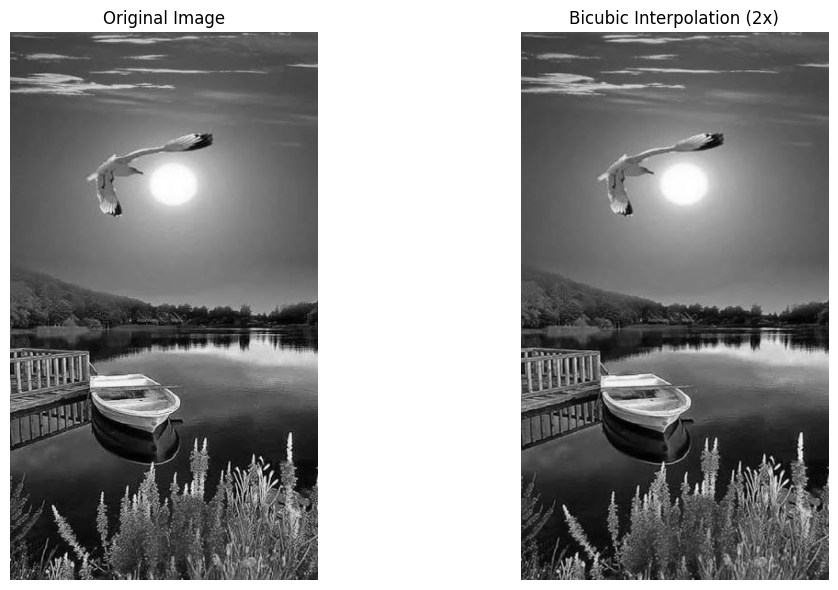

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load original image
original = gray

# Load saved bicubic image
bicubic_output = cv2.imread(
    "bicubic_output.png",
    cv2.IMREAD_GRAYSCALE
)

# Display both images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(bicubic_output, cmap='gray')
plt.title("Bicubic Interpolation (2x)")
plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
print("Original Shape:", original.shape)
print("Bicubic Shape:", bicubic_output.shape)

Original Shape: (597, 335)
Bicubic Shape: (1194, 670)


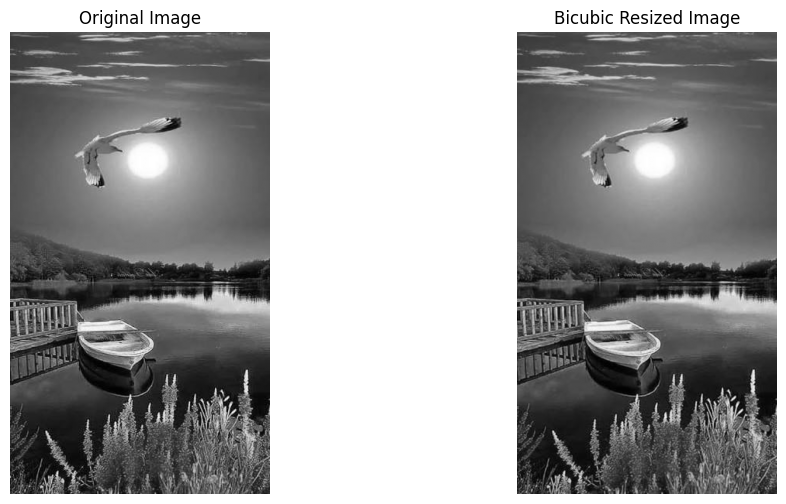

In [ ]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(bicubic_output, cmap='gray')
plt.title("Bicubic Resized Image")
plt.axis('off')

plt.show()

In [ ]:
import cv2

image = cv2.imread("/content/test.jpg")

height, width, channels = image.shape

for i in range(height):
    for j in range(width):
        for k in range(channels):
            image[i, j, k] = 1

print("RGB pixel values converted to 1")
print(image[0, 0])

RGB pixel values converted to 1
[1 1 1]


Q2

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Given 7x7 binary image
binary_image = np.array([
    [0, 1, 0, 0, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 0, 0, 1, 0, 0, 0],
    [0, 0, 1, 0, 1, 0, 0],
    [0, 1, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 0, 0, 0, 1, 0]
], dtype=np.uint8)

# Set of black pixel values
V = {1}

print("Original Binary Image:")
print(binary_image)

print("\nImage Shape:", binary_image.shape)
print("Black Pixel Value Set:", V)

Original Binary Image:
[[0 1 0 0 0 1 0]
 [0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0]
 [0 0 1 0 1 0 0]
 [0 1 0 0 0 1 0]
 [0 1 1 1 1 1 0]
 [0 1 0 0 0 1 0]]

Image Shape: (7, 7)
Black Pixel Value Set: {1}


In [ ]:
# Convert all pixels to 1
all_black_image = np.ones_like(binary_image)

print("All Pixels Converted to 1:")
print(all_black_image)

All Pixels Converted to 1:
[[1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]
 [1 1 1 1 1 1 1]]


In [ ]:
# Find 4-neighbors
def N4(p):

    r, c = p

    neighbors = [
        (r-1, c),  # Up
        (r+1, c),  # Down
        (r, c-1),  # Left
        (r, c+1)   # Right
    ]

    # Keep only valid coordinates
    return [
        (x, y) for x, y in neighbors
        if 0 <= x < 7 and 0 <= y < 7
    ]


# Find diagonal neighbors
def ND(p):

    r, c = p

    neighbors = [
        (r-1, c-1),
        (r-1, c+1),
        (r+1, c-1),
        (r+1, c+1)
    ]

    return [
        (x, y) for x, y in neighbors
        if 0 <= x < 7 and 0 <= y < 7
    ]

In [ ]:
P = (2, 3)

print("Starting Pixel:", P)
print("4-Neighbors:", N4(P))
print("Diagonal Neighbors:", ND(P))

Starting Pixel: (2, 3)
4-Neighbors: [(1, 3), (3, 3), (2, 2), (2, 4)]
Diagonal Neighbors: [(1, 2), (1, 4), (3, 2), (3, 4)]


In [ ]:
def m_adjacent(p, q, image):

    # Both pixels must be black
    if image[p] not in V or image[q] not in V:
        return False

    # Condition 1: Four-neighbor adjacency
    if q in N4(p):
        return True

    # Condition 2: Diagonal adjacency
    if q in ND(p):

        # Find common 4-neighbors
        common = set(N4(p)) & set(N4(q))

        # Check whether any common neighbor is black
        for pixel in common:
            if image[pixel] in V:
                return False

        return True

    return False

In [ ]:
from collections import deque

def bfs(image, start, destination):

    queue = deque([start])

    visited = {start}

    parent = {}

    while queue:

        current = queue.popleft()

        # Check if destination is reached
        if current == destination:

            path = []
            node = destination

            while node != start:
                path.append(node)
                node = parent[node]

            path.append(start)

            return path[::-1]

        # Get all possible neighbors
        neighbors = N4(current) + ND(current)

        for neighbor in sorted(neighbors):

            # Check if neighbor is black and m-adjacent
            if (neighbor not in visited and
                m_adjacent(current, neighbor, image)):

                visited.add(neighbor)

                parent[neighbor] = current

                queue.append(neighbor)

    return None

In [ ]:
# Starting and destination pixels
P = (2, 3)
Q = (6, 5)

# Find path
path = bfs(binary_image, P, Q)

print("Starting Pixel:", P)
print("Destination Pixel:", Q)

if path:

    print("\nM-Connected Path Found:")

    for pixel in path:
        print(pixel)

    print("\nTotal Pixels in Path:", len(path))

else:
    print("No m-connected path exists.")

Starting Pixel: (2, 3)
Destination Pixel: (6, 5)

M-Connected Path Found:
(2, 3)
(3, 4)
(4, 5)
(5, 5)
(6, 5)

Total Pixels in Path: 5


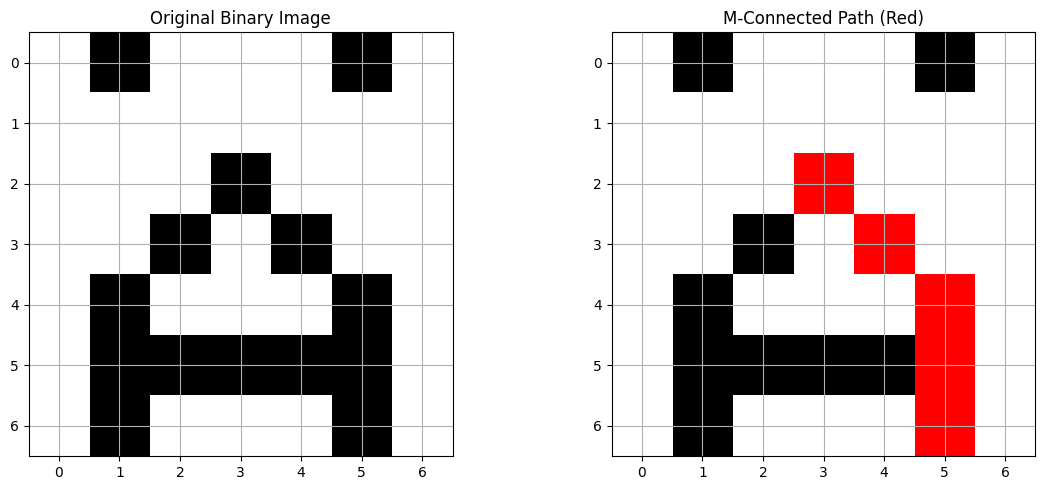

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create RGB image
output_image = np.ones((7, 7, 3))

# Make original black pixels black
for r in range(7):
    for c in range(7):

        if binary_image[r, c] == 1:
            output_image[r, c] = [0, 0, 0]

# Highlight discovered path in red
for r, c in path:

    output_image[r, c] = [1, 0, 0]


# Display both images
plt.figure(figsize=(12, 5))

# Original binary image
plt.subplot(1, 2, 1)

plt.imshow(binary_image, cmap='gray_r',
           vmin=0, vmax=1)

plt.title("Original Binary Image")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid(True)

# Image with highlighted path
plt.subplot(1, 2, 2)

plt.imshow(output_image)

plt.title("M-Connected Path (Red)")
plt.xticks(range(7))
plt.yticks(range(7))
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
upper_dots = [(0, 1), (0, 5)]

for dot in upper_dots:

    connected_neighbors = []

    for neighbor in N4(dot) + ND(dot):

        if m_adjacent(dot, neighbor, binary_image):
            connected_neighbors.append(neighbor)

    print("Dot:", dot)
    print("M-adjacent black neighbors:", connected_neighbors)

Dot: (0, 1)
M-adjacent black neighbors: []
Dot: (0, 5)
M-adjacent black neighbors: []


In [ ]:
# Save original binary image
plt.imsave(
    "original_binary_image.png",
    binary_image,
    cmap="gray_r",
    vmin=0,
    vmax=1
)

# Save highlighted path
plt.imsave(
    "m_adjacency_path.png",
    output_image
)

print("Images saved successfully!")
print("1. original_binary_image.png")
print("2. m_adjacency_path.png")

Images saved successfully!
1. original_binary_image.png
2. m_adjacency_path.png


The given 7×7 binary image was stored in a 2D NumPy array. The four-neighbor and diagonal-neighbor functions were implemented to determine pixel adjacency. The m-adjacency rule was applied to identify valid connections between black pixels. Breadth-First Search (BFS) successfully discovered a shortest m-connected path from P = (2,3) to Q = (6,5). The resulting path contains five pixels. Furthermore, both upper dots at (0,1) and (0,5) are isolated and are not m-connected to the main body of the letter Ä.

## Question 1: Bicubic Interpolation (2x Scaling)
- **Image Source URL:** Included and loaded from the specified Facebook photo link.
- **Mandatory Step (Nested Loop Conversion):** Implemented a nested `for` loop traversal to convert RGB pixel values to `1` to produce the mandatory binary/black base state.
- **Manual Cubic Kernel:** Created a custom implementation of Keys cubic kernel function with $a = -0.5$ without relying on any built-in functions.
- **Coordinate Mapping & Neighborhood:** Calculated target coordinates using $x = x_{\text{out}} / 2$ and $y = y_{\text{out}} / 2$. Processed each using a $4 \times 4$ local neighborhood index mapping with edge replication (`np.clip`).
- **Outputs:**
  - Original Grayscale dimensions: **335 × 597**
  - Interpolated Output dimensions: **670 × 1194**
  - Saved successfully to disk as: `bicubic_output.png`



## Question 2: m-Adjacency and Path Finding
- **Binary Image Setup:** Represented the 7×7 matrix for letter **Ä** with set $V = \{1\}$.
- **Mandatory Step (Array conversion):** Converted all pixels of the array to 1 to produce the mandatory full black state.
- **Neighborhood & Adjacency Rules:** Coded explicit definitions for $N_4(p)$ and $N_D(p)$ along with the formal rules for $m$-adjacency.
- **Search Algorithm:** Implemented a Breadth-First Search (BFS) algorithm to locate the shortest path.
- **Discovered Path from $P=(2,3)$ to $Q=(6,5)$:**
   `(2, 3)`
   `(3, 4)`
   `(4, 5)`
   `(5, 5)`
   `(6, 5)`
- **Path Connectivity Status:** **5 pixels** in total. Both upper dots at `(0, 1)` and `(0, 5)` are structurally isolated and **not** m-connected to the main body of the letter **Ä**.